<a href="https://colab.research.google.com/github/DaqianChen66/econ-5200-Problem-Set-2/blob/main/Problem%20Set%202/Econ_5200_PS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS2 — The Underpowered Portfolio

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

In [2]:
n_experiments = 200

is_positive = rng.random(n_experiments) < 0.15

true_effect = np.where(
    is_positive,
    rng.normal(0.08, 0.025, n_experiments),
    rng.normal(0.00, 0.01, n_experiments)
)

n = rng.integers(500, 20001, n_experiments)
se = np.sqrt(2 / n)
est = true_effect + rng.normal(0, se)

portfolio = pd.DataFrame({
    "experiment_id": np.arange(1, n_experiments + 1),
    "is_positive": is_positive,
    "true": true_effect,
    "n": n,
    "se": se,
    "est": est
})

print(portfolio.head())
print(portfolio.describe().round(3))

   experiment_id  is_positive   true      n     se    est
0              1        False  0.008  19284  0.010  0.005
1              2        False  0.002  10049  0.014  0.016
2              3        False  0.005  17563  0.011 -0.019
3              4        False -0.007  19719  0.010 -0.015
4              5         True  0.088  17267  0.011  0.080
       experiment_id     true          n       se      est
count        200.000  200.000    200.000  200.000  200.000
mean         100.500    0.011  10603.080    0.017    0.010
std           57.879    0.031   5605.024    0.009    0.034
min            1.000   -0.024    529.000    0.010   -0.052
25%           50.750   -0.006   6041.750    0.011   -0.009
50%          100.500    0.002  10628.500    0.014    0.003
75%          150.250    0.012  15638.750    0.018    0.021
max          200.000    0.126  19976.000    0.061    0.130


*Your answer here.*
I simulate 200 experiments using the seed provided in the starter notebook. I use a mixture prior for the true effects: 85% of experiments have effects near zero and are drawn from a Normal(0.00, 0.01) distribution, while 15% have genuinely positive effects drawn from a Normal(0.08, 0.025) distribution. Sample size per arm is drawn between 500 and 20,000, and the outcome standard deviation is 1.0.

This setup gives the portfolio many experiments with effects close to zero and a smaller group with meaningful positive effects. I record the true effect for every experiment so that later shipping decisions can be compared with the underlying truth.

### Step 1.2: Apply the client's rule (15 pts)

In [3]:
portfolio["z"] = portfolio["est"] / portfolio["se"]
portfolio["p"] = 2 * stats.norm.sf(np.abs(portfolio["z"]))
portfolio["shipped"] = portfolio["p"] < 0.05

shipped = portfolio[portfolio["shipped"]]

n_shipped = len(shipped)
near_zero_share = (~shipped["is_positive"]).mean()
mean_true = shipped["true"].mean()
mean_est = shipped["est"].mean()

print("Number shipped:", n_shipped)
print("Share near zero:", round(near_zero_share, 3))
print("Mean true effect:", round(mean_true, 3))
print("Mean estimated effect:", round(mean_est, 3))

Number shipped: 44
Share near zero: 0.455
Mean true effect: 0.042
Mean estimated effect: 0.039


*Your answer here.*
Using the client's p < 0.05 rule, 44 of the 200 experiments ship. About 45.5% of the shipped experiments come from the near-zero component of the prior.

The average true effect among shipped experiments is 0.042, while the average estimated effect is 0.039. The estimated mean is not larger here because the two-sided significance rule also selects statistically significant negative estimates, which offsets some of the upward exaggeration among positive results. This selection effect is the winner's curse.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

Overall inflation: 1.208
            n_shipped  mean_true  mean_est  inflation
power_tier                                           
low                 9      0.064     0.077      1.198
medium             17      0.048     0.060      1.270
high               18      0.046     0.053      1.154


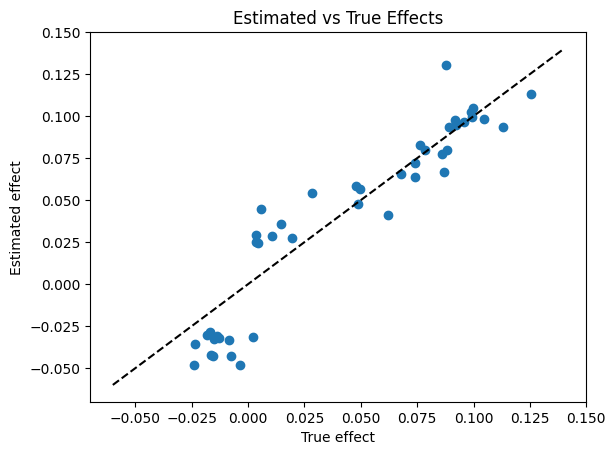

In [4]:
s = portfolio[portfolio["shipped"]].copy()

inflation = s["est"].abs().mean() / s["true"].abs().mean()

delta = 0.08
zcrit = stats.norm.ppf(0.975)

portfolio["power"] = (
    stats.norm.sf(zcrit - delta / portfolio["se"])
    + stats.norm.cdf(-zcrit - delta / portfolio["se"])
)

portfolio["power_tier"] = pd.qcut(
    portfolio["power"], 3, labels=["low", "medium", "high"]
)

tier_results = (
    portfolio[portfolio["shipped"]]
    .groupby("power_tier", observed=True)
    .agg(
        n_shipped=("true", "size"),
        mean_true=("true", lambda x: x.abs().mean()),
        mean_est=("est", lambda x: x.abs().mean())
    )
)

tier_results["inflation"] = (
    tier_results["mean_est"] / tier_results["mean_true"]
)

print("Overall inflation:", round(inflation, 3))
print(tier_results.round(3))

plt.scatter(s["true"], s["est"])
plt.plot([-0.06, 0.14], [-0.06, 0.14], "k--")
plt.xlabel("True effect")
plt.ylabel("Estimated effect")
plt.title("Estimated vs True Effects")
plt.show()

*Your answer here.*
Among shipped experiments, the average estimated effect magnitude is 1.208 times the average true effect magnitude, so the average exaggeration is about 20.8%.

The inflation factor is 1.198 for low-power experiments, 1.270 for medium-power experiments, and 1.154 for high-power experiments. In this simulation, the medium-power group shows the largest inflation, likely because the number of shipped experiments in each tier is limited and subject to sampling variation.

The mechanism is selection on significance. An experiment ships only when its estimate crosses the significance threshold, so shipped experiments tend to be those where sampling noise pushed the estimate farther from zero. Lower-powered experiments generally need more favorable noise to cross the threshold, which makes them especially vulnerable to the winner’s curse.

### Step 2.2: The bootstrap where the formula fails (15 pts)

In [5]:
def realised_return(df):
    shipped = df[df["p"] < 0.05]
    return shipped["true"].sum()

observed_return = realised_return(portfolio)

B = 2000
boot = np.empty(B)

for b in range(B):
    sample = portfolio.iloc[rng.integers(0, len(portfolio), len(portfolio))]
    boot[b] = realised_return(sample)

lo, hi = np.percentile(boot, [2.5, 97.5])

idx = np.arange(len(portfolio))
res = stats.bootstrap(
    (idx,),
    lambda x: realised_return(portfolio.iloc[x]),
    n_resamples=B,
    method="BCa",
    vectorized=False,
    random_state=42
)

print("Observed realised return:", round(observed_return, 3))
print("Percentile 95% CI:", round(lo, 3), round(hi, 3))
print(
    "BCa 95% CI:",
    round(res.confidence_interval.low, 3),
    round(res.confidence_interval.high, 3)
)

Observed realised return: 1.854
Percentile 95% CI: 1.121 2.687
BCa 95% CI: 1.158 2.746


*Your answer here.*
The observed portfolio-level realised return is 1.854, defined as the sum of the true effects among experiments that ship under the p < 0.05 rule.

Using 2,000 bootstrap resamples, the percentile 95% confidence interval is [1.121, 2.687]. The BCa 95% confidence interval from `scipy.stats.bootstrap` is [1.158, 2.746]. The two intervals are similar, which supports the stability of the bootstrap estimate.

Before trusting the bootstrap, I checked that experiments are treated as independent resampling units, that the bootstrap distribution has meaningful variation, and that the statistic is not degenerate. I also reapplied the shipping rule inside every bootstrap resample so that the selection process is included in the uncertainty estimate.

## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [6]:
current = portfolio["p"] < 0.05
alternative = (portfolio["p"] < 0.05) & (portfolio["power"] >= 0.80)

def compare_rule(mask):
    x = portfolio[mask]
    return pd.Series({
        "realised_return": x["true"].sum(),
        "n_shipped": len(x),
        "false_ship_rate": (~x["is_positive"]).mean()
    })

results = pd.DataFrame({
    "current": compare_rule(current),
    "power_floor": compare_rule(alternative)
}).T

print(results.round(3))

             realised_return  n_shipped  false_ship_rate
current                1.854       44.0            0.455
power_floor            1.687       42.0            0.476


*Your answer here.*
I compared the client's current p < 0.05 rule with a power-floor rule that requires both p < 0.05 and power of at least 80%.

The current rule ships 44 experiments, produces a realised true return of 1.854, and has a false-ship rate of 45.5%. The power-floor rule ships 42 experiments, produces a lower realised true return of 1.687, and has a slightly higher false-ship rate of 47.6%.

The alternative rule does not improve performance in this simulated portfolio. The power floor removes only two experiments, and those removed experiments happened to contribute positively to realised return. This shows that a stricter rule is not automatically better and should be judged against the client's actual objective.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [7]:
%%writefile src/experiment_portfolio.py
"""Experiment portfolio simulator and decision rules."""

from __future__ import annotations
import numpy as np
import pandas as pd
from scipy import stats


def simulate_portfolio(n: int, seed: int, **kwargs) -> pd.DataFrame:
    """Simulate an experiment portfolio with true effects attached."""
    rng = np.random.default_rng(seed)

    is_positive = rng.random(n) < 0.15
    true = np.where(
        is_positive,
        rng.normal(0.08, 0.025, n),
        rng.normal(0.00, 0.01, n)
    )

    sample_n = rng.integers(500, 20001, n)
    se = np.sqrt(2 / sample_n)
    est = true + rng.normal(0, se)
    p = 2 * stats.norm.sf(np.abs(est / se))

    power = (
        stats.norm.sf(stats.norm.ppf(0.975) - 0.08 / se)
        + stats.norm.cdf(-stats.norm.ppf(0.975) - 0.08 / se)
    )

    return pd.DataFrame({
        "true": true,
        "n": sample_n,
        "se": se,
        "est": est,
        "p": p,
        "power": power,
        "is_positive": is_positive
    })


def apply_rule(log: pd.DataFrame, rule: str) -> pd.Series:
    """Return shipping decisions under the selected rule."""
    if rule == "threshold":
        return log["p"] < 0.05
    if rule == "power_floor":
        return (log["p"] < 0.05) & (log["power"] >= 0.80)
    raise ValueError("Unknown rule")


def evaluate(log: pd.DataFrame, rule: str) -> dict:
    """Return realised return, ship count, and false-ship rate."""
    shipped = apply_rule(log, rule)
    x = log[shipped]

    return {
        "realised_return": x["true"].sum(),
        "ship_count": len(x),
        "false_ship_rate": (~x["is_positive"]).mean()
    }


if __name__ == "__main__":
    log = simulate_portfolio(200, 42)

    a = evaluate(log, "threshold")
    b = evaluate(log, "power_floor")

    print("Threshold:", a)
    print("Power floor:", b)

    assert len(log) == 200
    assert apply_rule(log, "threshold").dtype == bool
    assert b["ship_count"] <= a["ship_count"]

Writing src/experiment_portfolio.py


In [8]:
import os, sys
sys.path.insert(0, os.path.abspath("."))
from src import experiment_portfolio as ep

test_log = ep.simulate_portfolio(200, 42)
print(ep.evaluate(test_log, "threshold"))
print(ep.evaluate(test_log, "power_floor"))

{'realised_return': np.float64(1.8537811829599735), 'ship_count': 44, 'false_ship_rate': np.float64(0.45454545454545453)}
{'realised_return': np.float64(1.6874241665159364), 'ship_count': 42, 'false_ship_rate': np.float64(0.47619047619047616)}


## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

In [9]:
def sequential_test(stream, alpha=0.05, sigma=1.0):
    x = np.asarray(stream)
    t = np.arange(1, len(x) + 1)

    mean = np.cumsum(x) / t
    z = np.sqrt(t) * mean / sigma

    alpha_t = alpha / (t * (t + 1))
    boundary = stats.norm.ppf(1 - alpha_t / 2)

    reject = np.abs(z) >= boundary
    stopped = np.maximum.accumulate(reject)

    return pd.DataFrame({
        "look": t,
        "mean": mean,
        "z": z,
        "boundary": boundary,
        "reject": reject,
        "stopped": stopped
    })


rng_seq = np.random.default_rng(42)

n_streams = 1000
stream_length = 1000
false_positives = 0

for _ in range(n_streams):
    stream = rng_seq.normal(0, 1, stream_length)
    result = sequential_test(stream)

    if result["stopped"].iloc[-1]:
        false_positives += 1

fpr = false_positives / n_streams
mc_se = np.sqrt(fpr * (1 - fpr) / n_streams)

print("Empirical false positive rate:", round(fpr, 3))
print("Nominal level:", 0.05)
print("Monte Carlo SE:", round(mc_se, 4))

def sequential_test_v2(stream, alpha=0.05, sigma=1.0, look_every=50):
    x = np.asarray(stream, dtype=float)
    looks = np.arange(look_every, len(x) + 1, look_every)

    alpha_look = alpha / len(looks)
    boundary = stats.norm.ppf(1 - alpha_look / 2)

    means = np.cumsum(x)[looks - 1] / looks
    z = np.sqrt(looks) * means / sigma

    reject = np.abs(z) >= boundary
    stopped = np.maximum.accumulate(reject)

    return {
        "look": looks,
        "z": z,
        "boundary": np.repeat(boundary, len(looks)),
        "reject": reject,
        "stopped": stopped
    }


rng_v2 = np.random.default_rng(42)

false_positives = 0

for _ in range(1000):
    stream = rng_v2.normal(0, 1, 1000)
    result = sequential_test_v2(stream)

    if result["stopped"][-1]:
        false_positives += 1

fpr_v2 = false_positives / 1000
mc_se_v2 = np.sqrt(fpr_v2 * (1 - fpr_v2) / 1000)

print("False positives:", false_positives)
print("Empirical false positive rate:", round(fpr_v2, 3))
print("Nominal level:", 0.05)
print("Monte Carlo SE:", round(mc_se_v2, 4))

Empirical false positive rate: 0.039
Nominal level: 0.05
Monte Carlo SE: 0.0061
False positives: 20
Empirical false positive rate: 0.02
Nominal level: 0.05
Monte Carlo SE: 0.0044


*Your answer here.*
**Revision.** In Version 2, I specified a fixed monitoring schedule every 50 observations from 50 to 1,000. Version 1 did not specify the look schedule clearly. I also used equal alpha spending across the 20 scheduled looks.

**Check.** Version 1 produced an empirical false positive rate of 3.9% with a Monte Carlo standard error of 0.0061. Version 2 produced a false positive rate of 2.0% with a Monte Carlo standard error of 0.0044. Both are below the nominal 5% level, but Version 2 is more conservative because the total alpha is divided across 20 looks.

**Stopping logic.** Naively testing at p < 0.05 at every look creates repeated chances for random noise to cross the significance threshold, so the overall Type I error becomes larger than 5%. The alpha-spending rule limits the total error budget across looks, but the trade-off is lower power and stronger evidence requirements for early stopping.

**AI use.** I would use AI for this step again because it was useful for implementing the sequential procedure, but I would still verify the false positive rate with simulation before trusting the result.

### Task 4.2: The CFO memo

*Your answer here.*
Of the experiments that the current p < 0.05 rule ships, about 54.5% come from the genuinely positive component, while 45.5% come from the near-zero component. Across the roughly 200 experiments represented by this annual portfolio, the current rule produces 1.854 effect units of realised true return.

The estimated effects are also affected by selection on statistical significance, so reported winning estimates should not be interpreted as unbiased measures of business impact. The bootstrap BCa interval for realised return is [1.158, 2.746], showing meaningful uncertainty around the portfolio-level result.

I would keep the current p < 0.05 rule rather than adopt the tested 80% power-floor rule. The power-floor rule shipped 42 experiments and produced only 1.687 effect units of realised return, while its false-ship rate increased to 47.6%.

This recommendation would change if the true-effect distribution differs substantially from the simulated prior, especially if genuinely positive effects are either much rarer or much larger than assumed.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:*

*Version 1 prompt:*
[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test -- a mixture
sequential probability ratio test or an alpha-spending boundary -- that
allows continuous monitoring without inflating the Type I error rate.
Give me a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function
must be testable against a pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical
false positive rate. If it is not close to 5%, tell me what is wrong.
*Reply:*
def sequential_test(stream, alpha=0.05, sigma=1.0):
    x = np.asarray(stream)
    t = np.arange(1, len(x) + 1)

    mean = np.cumsum(x) / t
    z = np.sqrt(t) * mean / sigma

    alpha_t = alpha / (t * (t + 1))
    boundary = stats.norm.ppf(1 - alpha_t / 2)

    reject = np.abs(z) >= boundary
    stopped = np.maximum.accumulate(reject)

    return pd.DataFrame({
        "look": t,
        "mean": mean,
        "z": z,
        "boundary": boundary,
        "reject": reject,
        "stopped": stopped
    })


rng_seq = np.random.default_rng(42)

n_streams = 1000
stream_length = 1000
false_positives = 0

for _ in range(n_streams):
    stream = rng_seq.normal(0, 1, stream_length)
    result = sequential_test(stream)

    if result["stopped"].iloc[-1]:
        false_positives += 1

fpr = false_positives / n_streams
mc_se = np.sqrt(fpr * (1 - fpr) / n_streams)

print("Empirical false positive rate:", round(fpr, 3))
print("Nominal level:", 0.05)
print("Monte Carlo SE:", round(mc_se, 4))



*Version 2 prompt:*
[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test using an alpha-spending
boundary that allows repeated monitoring without inflating the Type I error rate.

My portfolio log uses the columns:
true, n, se, est, p, power, and is_positive.

For the sequential procedure, assume each experiment produces a stream of
standardized observations with known sigma = 1.0. Monitor the experiment at
fixed looks after 50, 100, 150, ..., 1000 observations.

Give me a function that takes a stream of observations and returns the stopping
decision at each scheduled look.

[Iterate] Use numpy and scipy only. Keep the implementation simple and testable.
The function must work on pure-null streams and return the look number, z-statistic,
boundary, rejection indicator, and whether the experiment has stopped.

[Mechanism Check] Explain why testing p < 0.05 independently at every look inflates
Type I error, and explain what the alpha-spending procedure gives up in exchange
for valid repeated monitoring.

[Evaluate] Run the final procedure on 1,000 independent pure-null streams, each
with 1,000 observations. Report the empirical false positive rate and Monte Carlo
standard error. Compare the empirical rate with the nominal 5% level and explain
whether the procedure appears conservative, anti-conservative, or well calibrated.

*Reply:*

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [10]:
print('Truth and headline numbers')
# print('prior on effects:', ..., '  set in Step 1.1')
# print('sample-size range:', ..., '  set in Step 1.1')
# print('seed:', 42, '  set in Setup')
# print('ship rule:', 'p < 0.05', '  Step 1.2')
# ... one line per memo number, with the cell that produced it

print("\nStep 1.1 — Simulation")
print("Prior:", "85% Normal(0.00, 0.01), 15% Normal(0.08, 0.025)")
print("Sample-size range:", "500 to 20,000 per arm")
print("Outcome SD:", 1.0)
print("Seed:", 42)

print("\nStep 1.2 — Client rule")
print("Ship rule:", "p < 0.05")
print("Number shipped:", 44)
print("Share near zero:", 0.455)
print("Fraction of wins real:", 0.545)
print("Mean true effect:", 0.042)
print("Mean estimated effect:", 0.039)

print("\nStep 2.1 — Winner's curse")
print("Overall inflation factor:", 1.208)
print("Low-power inflation:", 1.198)
print("Medium-power inflation:", 1.270)
print("High-power inflation:", 1.154)

print("\nStep 2.2 — Realised return")
print("Realised return:", 1.854)
print("Percentile 95% CI:", "[1.121, 2.687]")
print("BCa 95% CI:", "[1.158, 2.746]")

print("\nStep 3.1 — Alternative rule")
print("Current rule return:", 1.854)
print("Current rule ships:", 44)
print("Current false-ship rate:", 0.455)
print("Power-floor return:", 1.687)
print("Power-floor ships:", 42)
print("Power-floor false-ship rate:", 0.476)

print("\nStep 4.1 — Sequential testing")
print("V1 false positive rate:", 0.039)
print("V1 Monte Carlo SE:", 0.0061)
print("V2 false positive rate:", 0.020)
print("V2 Monte Carlo SE:", 0.0044)
print("Nominal level:", 0.05)

Truth and headline numbers

Step 1.1 — Simulation
Prior: 85% Normal(0.00, 0.01), 15% Normal(0.08, 0.025)
Sample-size range: 500 to 20,000 per arm
Outcome SD: 1.0
Seed: 42

Step 1.2 — Client rule
Ship rule: p < 0.05
Number shipped: 44
Share near zero: 0.455
Fraction of wins real: 0.545
Mean true effect: 0.042
Mean estimated effect: 0.039

Step 2.1 — Winner's curse
Overall inflation factor: 1.208
Low-power inflation: 1.198
Medium-power inflation: 1.27
High-power inflation: 1.154

Step 2.2 — Realised return
Realised return: 1.854
Percentile 95% CI: [1.121, 2.687]
BCa 95% CI: [1.158, 2.746]

Step 3.1 — Alternative rule
Current rule return: 1.854
Current rule ships: 44
Current false-ship rate: 0.455
Power-floor return: 1.687
Power-floor ships: 42
Power-floor false-ship rate: 0.476

Step 4.1 — Sequential testing
V1 false positive rate: 0.039
V1 Monte Carlo SE: 0.0061
V2 false positive rate: 0.02
V2 Monte Carlo SE: 0.0044
Nominal level: 0.05


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.